<a href="https://colab.research.google.com/github/majumder-upom/Project/blob/main/Quadrat_Diversity_Analysis_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plant Population & Species Diversity Analysis (Quadrat Method)
Botanical Garden, Jahangirnagar University


In [6]:
from google.colab import drive, files
drive.mount('/content/drive')

path = "/content/drive/MyDrive/Colab Notebooks/project/Plant_Population_Species_Diversity_Analysis.xlsx"

import os
print("File found:", os.path.exists(path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File found: True


In [10]:
#Read table
import numpy as np
import pandas as pd
raw = pd.read_excel(path, sheet_name=0, header=3)
raw.columns = [str(c).strip() for c in raw.columns]

quad_cols = [c for c in raw.columns if c.startswith("Q") and c[1:].isdigit()]
df = raw[["Scientific Name", "Family"] + quad_cols].copy()
df = df.dropna(subset=["Scientific Name", "Family"])
df[quad_cols] = df[quad_cols].fillna(0).astype(int)
df = df.reset_index(drop=True)

print(f"{len(df)} species rows, {len(quad_cols)} quadrats: {quad_cols}")
df.head()

46 species rows, 5 quadrats: ['Q1', 'Q2', 'Q3', 'Q4', 'Q5']


,Scientific Name,Family,Q1,Q2,Q3,Q4,Q5
0,Spilanthes acmella,Asteraceae,26,32,21,38,44
1,Cynodon dactylon,Poaceae,26,30,24,28,23
2,Wedelia trilobata,Asteraceae,19,23,36,43,43
3,Mimosa pudica,Fabaceae,5,12,8,5,18
4,Centella asiatica,Apiaceae,22,8,0,12,18


In [11]:
#data check
print("Duplicate species names:", df["Scientific Name"].duplicated().sum())
print("Negative counts:", int((df[quad_cols] < 0).sum().sum()))

df["ni"] = df[quad_cols].sum(axis=1)
never_found = df.loc[df["ni"] == 0, "Scientific Name"].tolist()
print("Species with 0 individuals:", never_found or "none")
df = df[df["ni"] > 0].reset_index(drop=True)
print("Species kept:", len(df))

Duplicate species names: 0
Negative counts: 0
Species with 0 individuals: ['Marsilea quadrifolia', 'Nicotiana plumbaginifolia']
Species kept: 44


## Step 2 – Read the quadrat table
The sheet has 4 title rows, then the header row. Total rows and blank rows are removed so only species remain.

In [ ]:
import numpy as np
import pandas as pd

raw = pd.read_excel(path, sheet_name=0, header=3)
raw.columns = [str(c).strip() for c in raw.columns]

quad_cols = [c for c in raw.columns if c.startswith("Q") and c[1:].isdigit()]
df = raw[["Scientific Name", "Family"] + quad_cols].copy()
df = df.dropna(subset=["Scientific Name", "Family"])          # drops Total row and notes
df[quad_cols] = df[quad_cols].fillna(0).astype(int)           # empty cell = 0 individuals
df = df.reset_index(drop=True)

print(f"{len(df)} species rows, {len(quad_cols)} quadrats: {quad_cols}")
df.head()

In [13]:
#abundance, frequency, density
N = df["ni"].sum()
df["pi"] = df["ni"] / N
df["Frequency_%"] = (df[quad_cols] > 0).sum(axis=1) / len(quad_cols) * 100
df["Density_per_quadrat"] = df["ni"] / len(quad_cols)
df["ln_pi"] = np.log(df["pi"])
df["pi_ln_pi"] = df["pi"] * df["ln_pi"]

df.sort_values("ni", ascending=False)[["Scientific Name", "Family", "ni", "pi", "Frequency_%", "Density_per_quadrat"]].head(5)

,Scientific Name,Family,ni,pi,Frequency_%,Density_per_quadrat
2,Wedelia trilobata,Asteraceae,164,0.155894,100.0,32.8
0,Spilanthes acmella,Asteraceae,161,0.153042,100.0,32.2
1,Cynodon dactylon,Poaceae,131,0.124525,100.0,26.2
8,Blumea lacera,Asteraceae,78,0.074144,100.0,15.6
7,Ichnocarpus frutescens,Apocynaceae,72,0.068441,100.0,14.4


In [14]:
#diversity indices
S = len(df)
H = -df["pi_ln_pi"].sum()
D = (df["pi"] ** 2).sum()
J = H / np.log(S)

indices = pd.DataFrame({
    "Index": ["Species richness (S)", "Total individuals (N)", "Shannon-Wiener H'",
              "Simpson D", "Simpson diversity 1-D", "Pielou evenness J'"],
    "Value": [S, N, round(H, 4), round(D, 4), round(1 - D, 4), round(J, 4)],
})
indices


,Index,Value
0,Species richness (S),44.0000
1,Total individuals (N),1052.0000
2,Shannon-Wiener H',2.7984
3,Simpson D,0.0891
4,Simpson diversity 1-D,0.9109
5,Pielou evenness J',0.7395


In [15]:
#fanily
fam = (df.groupby("Family")
         .agg(Species=("Scientific Name", "count"), Individuals=("ni", "sum"))
         .assign(Relative_abundance=lambda t: t["Individuals"] / N,
                 Percent_share=lambda t: t["Individuals"] / N * 100)
         .sort_values("Individuals", ascending=False))
fam.round(4)

,Species,Individuals,Relative_abundance,Percent_share
Family,,,,
Asteraceae,8,452,0.4297,42.9658
Poaceae,6,144,0.1369,13.6882
Apocynaceae,3,142,0.1350,13.4981
Cleomaceae,1,63,0.0599,5.9886
Apiaceae,1,60,0.0570,5.7034
Fabaceae,3,60,0.0570,5.7034
Acanthaceae,2,39,0.0371,3.7072
Amaranthaceae,3,16,0.0152,1.5209
Rubiaceae,1,10,0.0095,0.9506


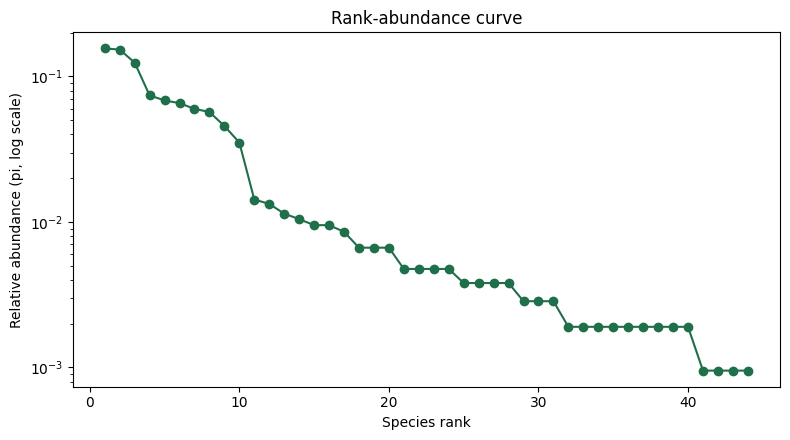

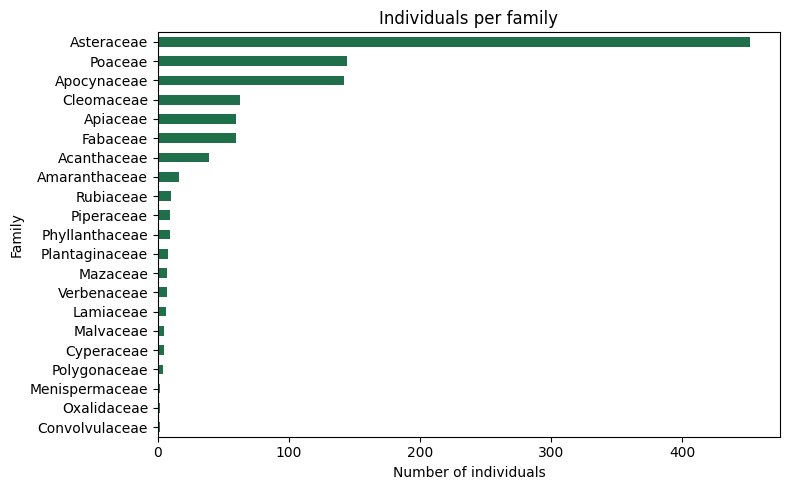

In [16]:
#Graph
import matplotlib.pyplot as plt

ranked = df.sort_values("ni", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, S + 1), ranked["pi"], marker="o", color="#1f6f4a")
ax.set_yscale("log")
ax.set_xlabel("Species rank")
ax.set_ylabel("Relative abundance (pi, log scale)")
ax.set_title("Rank-abundance curve")
plt.tight_layout(); plt.savefig("rank_abundance.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
fam["Individuals"].sort_values().plot.barh(ax=ax, color="#1f6f4a")
ax.set_xlabel("Number of individuals")
ax.set_title("Individuals per family")
plt.tight_layout(); plt.savefig("family_abundance.png", dpi=200); plt.show()